In [ ]:
from google.colab import drive
import os
import shutil

# 1. Google Drive'ı Bağla
drive.mount('/content/drive')

# 2. Drive'dan yedeklenen dosyaları yerel disk alanına kopyala
print("Yedek dosyaları Google Drive'dan indiriliyor...")
shutil.copy('/content/drive/My Drive/opencv_cuda/cv2_cuda_backup.zip', '/content/')
shutil.copy('/content/drive/My Drive/opencv_cuda/opencv_libs_backup.zip', '/content/')

# 3. Python paket klasörünü oluştur ve dosyaları çıkart
print("Python cv2 paketi kuruluyor...")
os.makedirs('/usr/local/lib/python3.13/dist-packages/cv2', exist_ok=True)
!unzip -q -o /content/cv2_cuda_backup.zip -d /usr/local/lib/python3.13/dist-packages/cv2

# 4. Paylaşılan C++ kütüphanelerini çıkart
print("Sistem paylaşımlı kütüphaneleri (.so) geri yükleniyor...")
!unzip -q -o /content/opencv_libs_backup.zip -d /usr/local/lib

# 5. Sistem dinamik kütüphane bağlayıcısını güncelle
print("Kütüphane yolları sistemde güncelleniyor...")
!ldconfig

# 6. Test Et
print("\n=== KURULUM TAMAMLANDI ===")
import cv2
cuda_devices = cv2.cuda.getCudaEnabledDeviceCount()
print(f"CUDA Destekli Cihaz Sayısı: {cuda_devices}")
if cuda_devices > 0:
    print("Tebrikler! OpenCV CUDA desteğiyle başarıyla geri yüklendi.")
    cv2.cuda.printCudaDeviceInfo(0)
else:
    print("Uyarı: Kurulum tamamlandı ancak GPU etkinleştirilmemiş olabilir. Runtime ayarlarından GPU seçtiğinize emin olun.")

Mounted at /content/drive
Yedek dosyaları Google Drive'dan indiriliyor...
Python cv2 paketi kuruluyor...
Sistem paylaşımlı kütüphaneleri (.so) geri yükleniyor...
Kütüphane yolları sistemde güncelleniyor...
/sbin/ldconfig.real: /usr/local/lib/libtbbbind_2_5.so.3 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libumf.so.1 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libtbb.so.12 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libtbbbind.so.3 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libur_adapter_level_zero.so.0 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libur_adapter_level_zero_v2.so.0 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libtbbmalloc_proxy.so.2 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libhwloc.so.15 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libur_adapter_opencl.so.0 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libjulia.so.1.12 is not a sym

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Görüntüleri gri tonlamalı (grayscale) olarak yükleyelim
img_left = cv2.imread('/content/görsel.png', cv2.IMREAD_GRAYSCALE)
img_right = cv2.imread('/content/görsel1.png', cv2.IMREAD_GRAYSCALE)

if img_left is None or img_right is None:
    print("Hata: Görüntüler yüklenemedi! Lütfen dosya yollarını kontrol edin.")
else:
    print(f"Sol Görüntü Boyutu: {img_left.shape}")
    print(f"Sağ Görüntü Boyutu: {img_right.shape}")

    # Görüntülerin boyutlarının aynı olduğundan emin olalım (gerekirse yeniden boyutlandırın)
    if img_left.shape != img_right.shape:
        img_right = cv2.resize(img_right, (img_left.shape[1], img_left.shape[0]))

Sol Görüntü Boyutu: (288, 384)
Sağ Görüntü Boyutu: (288, 384)


In [2]:
# 2. StereoBM Yöntemi ile Fark Haritası (Disparity Map) Oluşturma
# numDisparities: Arama menzili, 16'nın katı olmalıdır.
# blockSize: Eşleştirme penceresi boyutu, 3, 5, 7 vb. tek sayı olmalıdır.
stereo_bm = cv2.StereoBM_create(numDisparities=64, blockSize=15)
disparity_bm = stereo_bm.compute(img_left, img_right)

# Görüntülemek için normalize edelim
disparity_bm_visual = cv2.normalize(disparity_bm, None, alpha=0, beta=255, norm_type=cv2.NORM_MINMAX, dtype=cv2.CV_8U)

In [3]:
# 3. StereoSGBM (Semi-Global Block Matching) Yöntemi
# Genellikle daha pürüzsüz ve gürültüsüz sonuçlar verir.
stereo_sgbm = cv2.StereoSGBM_create(
    minDisparity=0,
    numDisparities=64,             # Arama menzili
    blockSize=5,                   # Pencere boyutu
    P1=8 * 3 * 5**2,               # Pürüzsüzlük cezası parametresi 1
    P2=32 * 3 * 5**2,              # Pürüzsüzlük cezası parametresi 2
    disp12MaxDiff=1,
    uniquenessRatio=15,
    speckleWindowSize=100,
    speckleRange=32
)
disparity_sgbm = stereo_sgbm.compute(img_left, img_right)

# Görüntülemek için normalize edelim
disparity_sgbm_visual = cv2.normalize(disparity_sgbm, None, alpha=0, beta=255, norm_type=cv2.NORM_MINMAX, dtype=cv2.CV_8U)

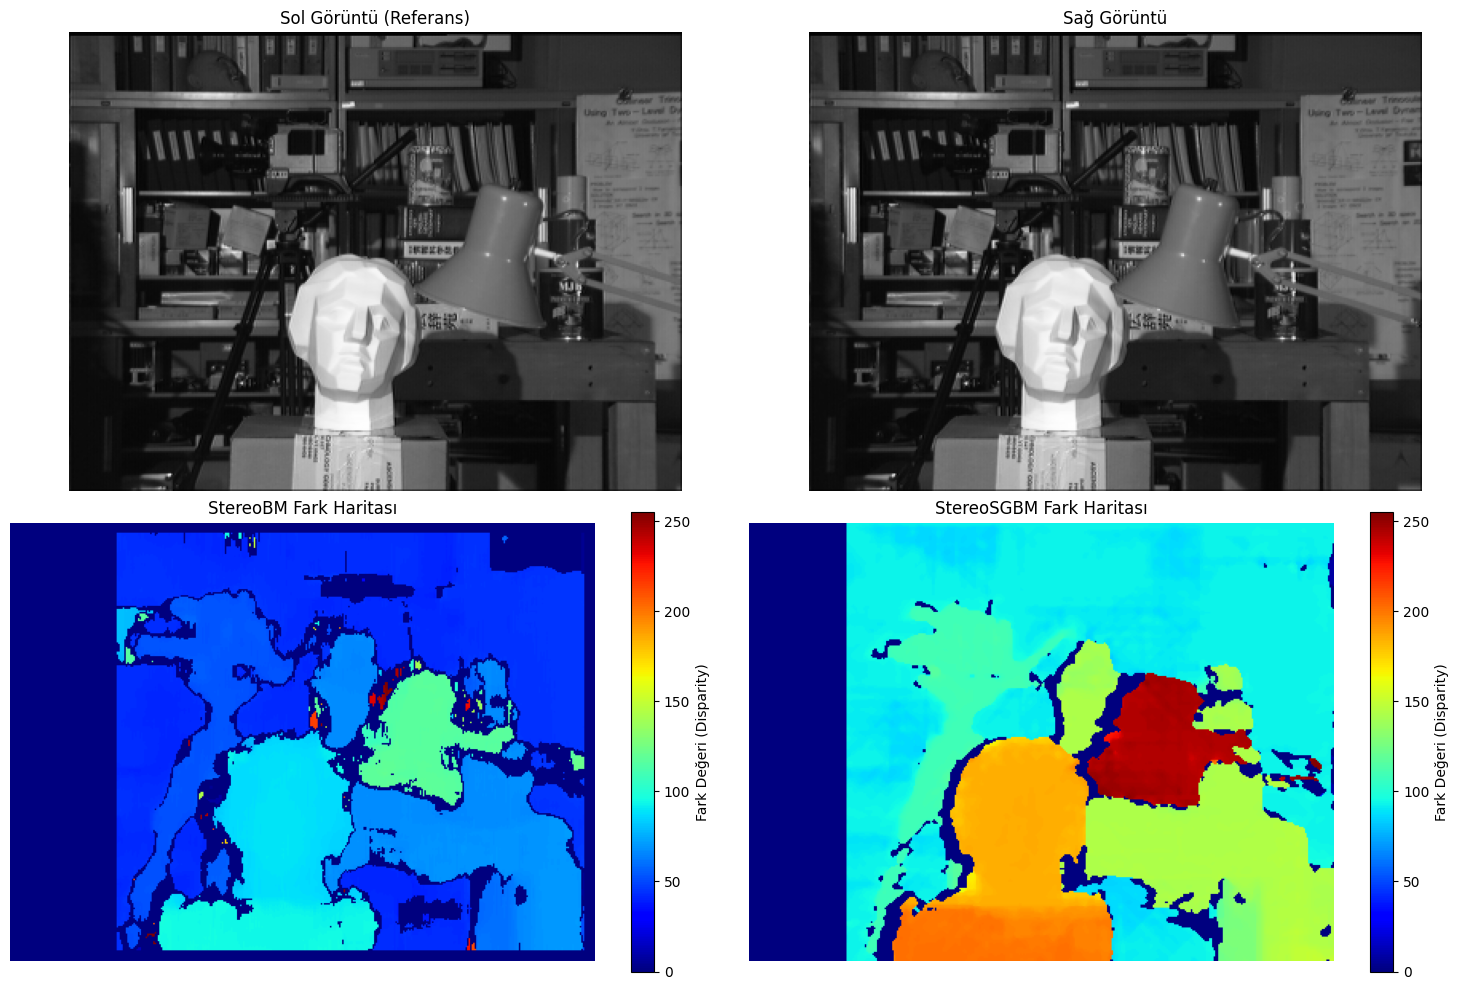

In [4]:
# 4. Sonuçları Görselleştirme
plt.figure(figsize=(15, 10))

plt.subplot(2, 2, 1)
plt.title("Sol Görüntü (Referans)")
plt.imshow(img_left, cmap='gray')
plt.axis('off')

plt.subplot(2, 2, 2)
plt.title("Sağ Görüntü")
plt.imshow(img_right, cmap='gray')
plt.axis('off')

plt.subplot(2, 2, 3)
plt.title("StereoBM Fark Haritası")
plt.imshow(disparity_bm_visual, cmap='jet')
plt.colorbar(label='Fark Değeri (Disparity)')
plt.axis('off')

plt.subplot(2, 2, 4)
plt.title("StereoSGBM Fark Haritası")
plt.imshow(disparity_sgbm_visual, cmap='jet')
plt.colorbar(label='Fark Değeri (Disparity)')
plt.axis('off')

plt.tight_layout()
plt.show()

### Fark Haritasındaki Renklerin Anlamı ve Yorumu

1. **Renklerin Anlamı:**
   * Fark haritasında (jet renk haritası kullanıldığında) **kırmızı/sıcak** tonlar daha yüksek piksel kaymasını (fark değerini) temsil eder. Bu durum, nesnenin kameraya **daha yakın** olduğunu gösterir.
   * **Mavi/soğuk** tonlar ise düşük piksel kaymasını temsil eder ve nesnenin kameraya **daha uzak** olduğunu ifade eder.
   * Bu durumun temel sebebi **paralaks (parallax)** etkisidir: Yakındaki nesneler iki kamera arasında yatay eksende çok daha fazla yer değiştirirken, uzaktaki nesneler neredeyse aynı konumda kalırlar.

2. **Gerçek Bir Derinlik Ölçümü Sağlar mı?**
   * **Doğrudan Hayır, Matematiksel Olarak Evet:** Elde edilen fark haritası (disparity map) doğrudan metre veya santimetre cinsinden gerçek bir derinlik (z) vermez; sadece pikseller arası kayma miktarını gösterir.
   * **Gerçek Derinliğe Dönüştürme:** Gerçek fiziksel derinliği ($Z$) elde etmek için stereo kamera sisteminin kalibre edilmesi ve şu formülün uygulanması gerekir:
     $$Z = \frac{f \cdot B}{d}$$
     * Burada $f$ kameranın odak uzaklığı (focal length),
     * $B$ iki kamera arasındaki fiziksel mesafe (baseline),
     * $d$ ise fark (disparity) değeridir.
   * Dolayısıyla, kamera matrisleri ve fiziksel yerleşim detayları bilinmiyorsa bu harita sadece **göreli (relative) bir derinlik** (hangisi daha yakında, hangisi uzakta) sunar. Kalibrasyon parametreleri mevcut olduğunda ise **gerçek metrik derinlik** hesaplanabilir.